In [52]:
import pandas as pd 
from sklearn.model_selection import train_test_split

df = pd.read_csv("data/processed/clean_insurance.csv")


In [53]:
features = ["age", "bmi", "smoker", "smoker_high_bmi", 'smoker_age']
X = df[features]
y = df["charges"]



In [54]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=16)

In [55]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score
import xgboost as xgb


models = {"Linear Regression": LinearRegression(), 
          "Random Forest": RandomForestRegressor(random_state=16),
          "XGBoost": xgb.XGBRegressor(random_state=42, n_estimators=100, learning_rate=0.1)
          }
r2_scores=[]
for i, model in models.items():

    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    r2= r2_score(y_test,predictions)
    r2_scores.append(r2)
    print(i, " and mae : ", mae, "and r2 :  ", r2)



Linear Regression  and mae :  2708.164955784499 and r2 :   0.8201512344095905
Random Forest  and mae :  2865.8623053853707 and r2 :   0.7910013763372046
XGBoost  and mae :  2820.9381473992685 and r2 :   0.7976709531807101


Let's take a look at the performance of these different models

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_70769/3328723577.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=models.keys(), y=r2_scores, palette='viridis')


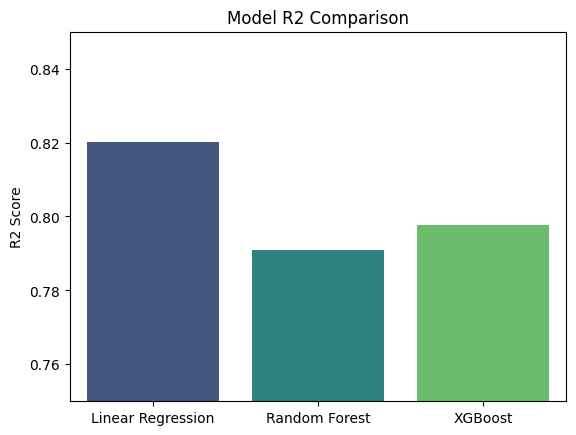

In [56]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.barplot(x=models.keys(), y=r2_scores, palette='viridis')
plt.title('Model R2 Comparison')
plt.ylabel('R2 Score')
plt.ylim(0.75, 0.85)
plt.show()

We will choose Linear Regression as a definitive model in this project.

/var/folders/4x/8yhzr1y14ld556ngskgq54000000gn/T/ipykernel_70769/740450944.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='vlag')


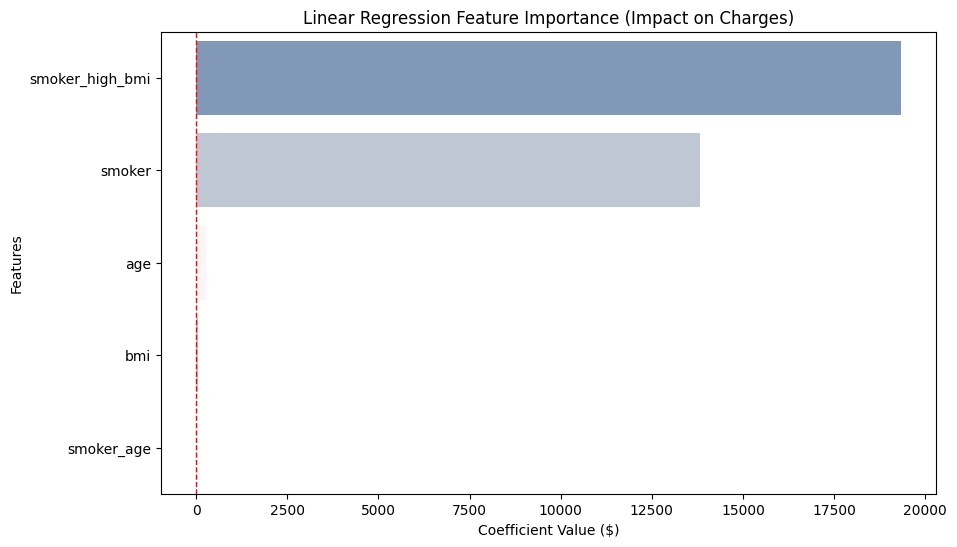

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

predictions = model.predict(X_test)
coef_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Coefficient': model.coef_
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()
coef_df = coef_df.sort_values(by='Abs_Coefficient', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=coef_df, x='Coefficient', y='Feature', palette='vlag')
plt.axvline(x=0, color='red', linestyle='--', linewidth=1)
plt.title('Linear Regression Feature Importance (Impact on Charges)')
plt.xlabel('Coefficient Value ($)')
plt.ylabel('Features')
plt.show()